Identificação e Definição do Problema
* Integrantes: Maicon Fonseca Dutra, Gabriel Caniza da Silva e Gabriel Vidal de Souza.
* Origem e autorização de uso da base: A base "International football results" foi extraída do Kaggle. É uma base de dados aberta e de uso livre.
* O que uma linha representa: Cada linha representa uma partida internacional oficial de futebol entre duas seleções.
* Pergunta do projeto: É possível prever qual seleção sairá vitoriosa numa partida internacional com base no histórico de confrontos, no tipo de torneio e no mando de campo?
* Tipo de tarefa: Classificação (prever uma categoria: Vitória do Mandante, Empate ou Vitória do Visitante).

In [4]:
import pandas as pd
from google.colab import files

arquivos = files.upload()
if len(arquivos) != 1:
    raise ValueError("Envie exatamente um arquivo para esta etapa.")
nome = next(iter(arquivos))

df = pd.read_csv(nome, sep=",", encoding="utf-8")
display(df.head())
print("Linhas e colunas:", df.shape)
df.info()
display(df.describe(include="all"))
display(df.isna().sum().sort_values(ascending=False))
print("Linhas duplicadas:", df.duplicated().sum())

Saving results.csv to results.csv


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


Linhas e colunas: (49945, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49945 entries, 0 to 49944
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        49945 non-null  object
 1   home_team   49945 non-null  object
 2   away_team   49945 non-null  object
 3   home_score  49945 non-null  int64 
 4   away_score  49945 non-null  int64 
 5   tournament  49945 non-null  object
 6   city        49945 non-null  object
 7   country     49945 non-null  object
 8   neutral     49945 non-null  bool  
dtypes: bool(1), int64(2), object(6)
memory usage: 3.1+ MB


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
count,49945,49945,49945,49945.000000,49945.000000,49945,49945,49945,49945
unique,16535,328,322,NaN,NaN,225,2107,269,2
top,2012-02-29,Brazil,Uruguay,NaN,NaN,Friendly,Kuala Lumpur,United States,False
freq,66,618,590,NaN,NaN,18263,748,1595,36669
mean,NaN,NaN,NaN,1.756072,1.182701,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,1.772078,1.401670,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,1.000000,0.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,NaN,NaN


,0
date,0
home_team,0
away_team,0
home_score,0
away_score,0
tournament,0
city,0
country,0
neutral,0


Linhas duplicadas: 0


Interpretação Exploratória (head, shape, info e describe)
* Resultados gerais: A nossa base tem exatamente 49.945 linhas e 9 colunas, o que é um volume excelente para o treino de Machine Learning. O comando `info` mostra que temos variáveis numéricas (`home_score`, `away_score`) e categóricas/texto (como `home_team`, `tournament`, `city`).
* Ausências e Duplicatas: O diagnóstico indicou 0 dados em falta (ausentes) e 0 linhas duplicadas. Como a base está perfeitamente limpa nestes aspetos, não precisaremos de aplicar técnicas de preenchimento (como colocar zeros) ou de remoção de registos nesta etapa inicial.

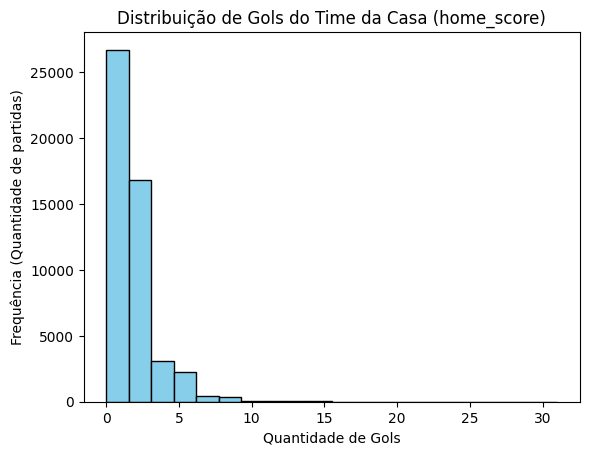

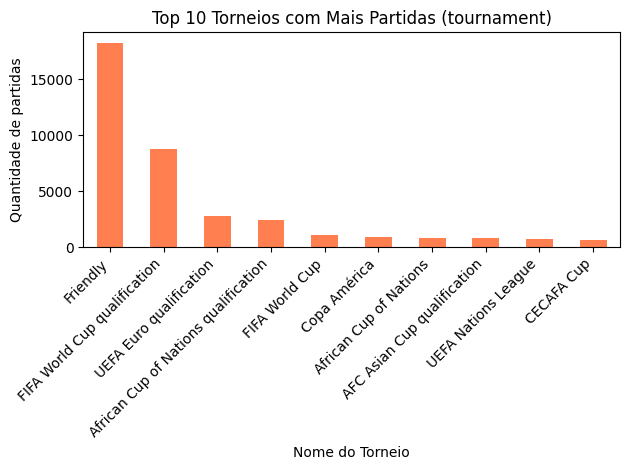

In [5]:
import matplotlib.pyplot as plt

# Gráfico 1: Histograma (Variável Numérica)
coluna_numerica = "home_score"
df[coluna_numerica].dropna().plot.hist(bins=20, color='skyblue', edgecolor='black')
plt.title("Distribuição de Gols do Time da Casa (home_score)")
plt.xlabel("Quantidade de Gols")
plt.ylabel("Frequência (Quantidade de partidas)")
plt.show()

# Gráfico 2: Barras (Variável Categórica)
coluna_categoria = "tournament"
df[coluna_categoria].value_counts().head(10).plot.bar(color='coral')
plt.title("Top 10 Torneios com Mais Partidas (tournament)")
plt.xlabel("Nome do Torneio")
plt.ylabel("Quantidade de partidas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Interpretação dos Gráficos
* Gráfico 1 (Histograma - Gols): O gráfico mostra uma distribuição concentrada à esquerda. Isto indica que, na grande maioria das partidas internacionais, a equipa da casa marca entre 0 e 2 gols. Goleadas extremas são eventos muito raros, o que faz sentido na realidade do futebol.
* Gráfico 2 (Barras - Torneios): Observamos que a categoria "Friendly" (Amigáveis) domina amplamente o número de registos na base de dados, seguida pelas eliminatórias do Campeonato do Mundo (FIFA World Cup qualification).

Features, Target e Limpeza
* Target (O que prever): O "Resultado da Partida" (Vitória da Casa, Empate ou Vitória do Visitante). Nota: Teremos de criar esta coluna condicional baseada na diferença entre `home_score` e `away_score` no futuro.
* Features (Entradas): Usaremos `home_team`, `away_team`, `tournament` e a variável booleana `neutral` (campo neutro).
* Colunas excluídas e justificativa: Colunas como `city` e a data exata em dias (`date`) poderão ser descartadas ou transformadas, pois a cidade específica tem menos peso do que o país em si para determinar o mando de campo, e datas exatas geram ruído para modelos de classificação simples.
* Limitações da base: Não temos dados sobre a equipa titular, faltas, posse de bola ou lesões dos jogadores no dia da partida, o que limita a previsibilidade exata do modelo.